In [1]:
"""Pa1 Perceptron code"""
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

In [2]:
class Perceptron:
    """Perceptron classifier.

    Parameters
    ------------
    eta : float
      Learning rate (between 0.0 and 1.0)
    n_iter : int
      Passes over the training dataset.
    random_state : int
      Random number generator seed for random weight
      initialization.

    Attributes
    -----------
    w_ : 1d-array
      Weights after fitting.
    b_ : Scalar
      Bias unit after fitting.
    errors_ : list
      Number of misclassifications (updates) in each epoch.

    """
    def __init__(self, eta=0.01, n_iter=50, random_state=1):
        self.eta = eta
        self.n_iter = n_iter
        self.random_state = random_state

    def fit(self, X, y):
        """Fit training data.

        Parameters
        ----------
        X : {array-like}, shape = [n_examples, n_features]
          Training vectors, where n_examples is the number of examples and
          n_features is the number of features.
        y : array-like, shape = [n_examples]
          Target values.

        Returns
        -------
        self : object

        """
        rgen = np.random.RandomState(self.random_state)
        self.w_ = rgen.normal(loc=0.0, scale=0.01, size=X.shape[1])
        self.b_ = np.float64(0.)
        
        self.errors_ = []

        for _ in range(self.n_iter):
            errors = 0
            for xi, target in zip(X, y):
                update = self.eta * (target - self.predict(xi))
                self.w_ += update * xi
                self.b_ += update
                errors += int(update != 0.0)
            self.errors_.append(errors)
        return self

    def net_input(self, X):
        """Calculate net input"""
        return np.dot(X, self.w_) + self.b_

    def predict(self, X):
        """Return class label after unit step"""
        return np.where(self.net_input(X) >= 0.0, 1, 0)



In [3]:
#reading the wine data
df = pd.read_csv('wine.data', header=0, encoding='utf-8')

In [4]:
df.head()

,Class,Alcohol,Malic acid,Ash,Alcalinity of ash,Magnesium,Total phenols,Flavanoids,Nonflavanoid phenols,Proanthocyanins,Color intensity,Hue,OD280/OD315 of diluted wines,Proline
0,1,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065
1,1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050
2,1,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185
3,1,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480
4,1,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735


In [5]:
#targets
y = df.iloc[:, 0].values #targets class

#features
X = df.drop(df.columns[[0, 5, 13]], axis=1).values  #all data except class,Magnesium,Proline

In [6]:
#split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y)

X_train, X_valid, y_train, y_valid = train_test_split(
    X_train, y_train, test_size=0.35, stratify=y_train)

models = []

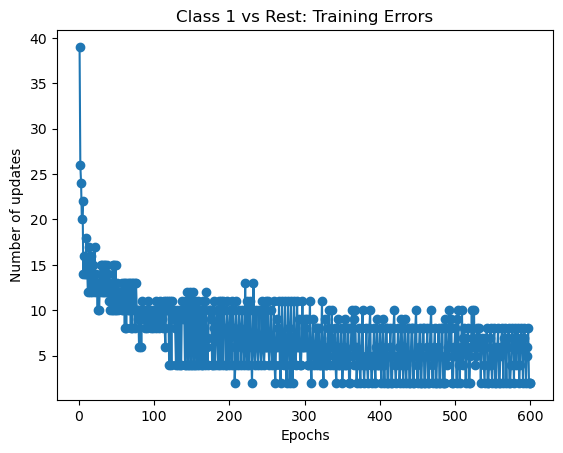

In [7]:
#target1
y_train_1 = np.where(y_train == 1, 1, 0) #class 1 vs all
y_valid_1 = np.where(y_valid == 1, 1, 0)

#training 
ppn = Perceptron(eta=0.1, n_iter=600) 
ppn.fit(X_train, y_train_1)
models.append(ppn)

#plot model1
plt.plot(range(1, len(ppn.errors_)+1), ppn.errors_, marker='o')
plt.xlabel('Epochs')
plt.ylabel('Number of updates')
plt.title(f'Class 1 vs Rest: Training Errors')
plt.show()

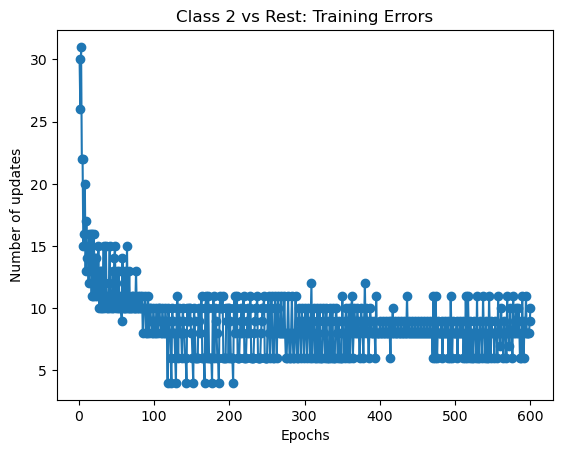

In [8]:
#target 2
y_train_2 = np.where(y_train == 2, 1, 0) #class 1 vs all
y_valid_2 = np.where(y_valid == 2, 1, 0)

#training 
ppn = Perceptron(eta=0.1, n_iter=600) 
ppn.fit(X_train, y_train_2)
models.append(ppn)

#plot model2
plt.plot(range(1, len(ppn.errors_)+1), ppn.errors_, marker='o')
plt.xlabel('Epochs')
plt.ylabel('Number of updates')
plt.title(f'Class 2 vs Rest: Training Errors')
plt.show()

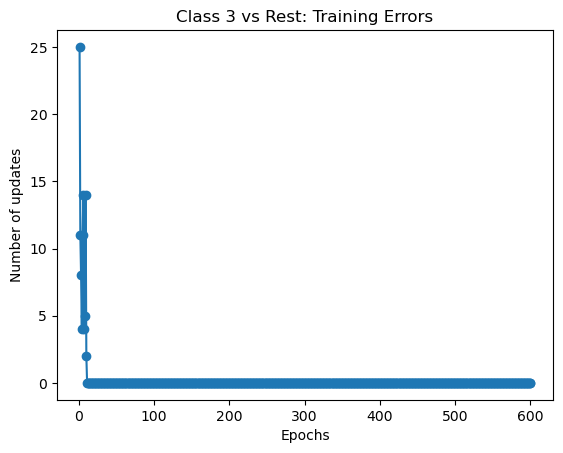

In [9]:
#target 3
y_train_3 = np.where(y_train == 3, 1, 0) #class 3 vs all
y_valid_3 = np.where(y_valid == 3, 1, 0)

#training 
ppn = Perceptron(eta=0.1, n_iter=600) 
ppn.fit(X_train, y_train_3)
models.append(ppn)

#plot model3
plt.plot(range(1, len(ppn.errors_)+1), ppn.errors_, marker='o')
plt.xlabel('Epochs')
plt.ylabel('Number of updates')
plt.title(f'Class 3 vs Rest: Training Errors')
plt.show()

Final Weights and Biases
-------------------------------------
Class 1 Model:
Weights: [  6.77724345   9.76488244  65.75271828 -18.64072969   4.77365408
  24.57998461  -5.26655188 -30.32061207  10.85619039   9.8685063
  29.76962108]
Bias: -16.29999999999996

-------------------------------------
Class 2 Model:
Weights: [  8.14024345 -21.05511756 -54.31828172   8.99927031  -2.53434592
  15.01098461   1.84944812   4.77438793 -27.79880961   0.7565063
 -18.03637892]
Bias: 15.59999999999996

-------------------------------------
Class 3 Model:
Weights: [-3.52475655  4.27688244 -0.48628172  1.32927031 -4.86334592 -9.98401539
  0.62244812 -3.10261207  9.18819039 -1.7344937  -6.42337892]
Bias: -0.4

-------------------------------------
Final Confusion Matrix:
[[12  0  0]
 [ 3 11  0]
 [ 3  0  7]]


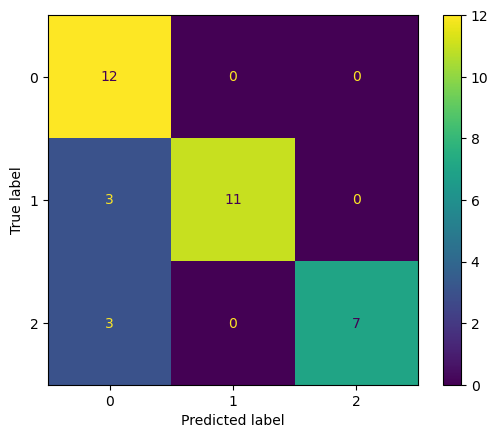


Classification Report:
              precision    recall  f1-score   support

           1       0.67      1.00      0.80        12
           2       1.00      0.79      0.88        14
           3       1.00      0.70      0.82        10

    accuracy                           0.83        36
   macro avg       0.89      0.83      0.83        36
weighted avg       0.89      0.83      0.84        36



In [10]:
#Multiclass Prediction Function
def predict_multiclass(X):
    scores = np.array([model.net_input(X) for model in models])
    return np.argmax(scores, axis=0) + 1  

#Final Evaluation

y_pred = predict_multiclass(X_test)

print("Final Weights and Biases")
print("-------------------------------------")
for i, model in enumerate(models, 1):
    print(f"Class {i} Model:")
    print(f"Weights: {model.w_}")
    print(f"Bias: {model.b_}\n")
    print("-------------------------------------")
print("Final Confusion Matrix:")
cm = confusion_matrix(y_test, y_pred)
print(cm)
ConfusionMatrixDisplay(cm).plot()
plt.show()

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

